# PA27 — Results Analysis

**Porto vs. Bragança | T3 Cold Stress | Winter Road-Service Operator**

This notebook analyses two incremental learning protocols:

**City-specific experiments**
- 2 cities
- 2 feature representations (A and B)
- 5 mandatory online classifiers
- 20 independent experiments

**Unified learning experiments**
- Selection of the best model–representation combination per city
- Selection criterion: Macro-F1, followed by positive-class Recall and computational cost
- One or two distinct selected configurations, depending on whether the city-specific winners coincide
- A shared incremental classifier trained with both city streams
- Separate predictive and computational evaluation for each city

Both protocols use the same eleven base predictors, a frozen Cold Stress threshold, the 2016–2017 warm-up, and the 2018–2025 prequential evaluation period.

The unified experiment is an exploratory comparison, because model selection uses results from the same evaluation period.

## 1. Setup

This cell locates the project root, imports the analysis libraries, and creates dedicated output folders for report-ready tables and figures.




In [22]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    # Find the repository root when the notebook is run from /notebooks or the project root.
    cwd = Path.cwd().resolve()

    for candidate in [cwd, *cwd.parents]:
        if (
            (candidate / "config").exists()
            and (candidate / "src").exists()
            and (candidate / "results").exists()
        ):
            return candidate

    if cwd.name == "notebooks":
        candidate = cwd.parent
        if (candidate / "config").exists() and (candidate / "src").exists():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root. "
        "Run this notebook from the repository or its notebooks/ directory."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.experiment import (
    CITY_A,
    CITY_B,
    MODEL_NAMES,
    REPRESENTATIONS,
    TARGET_COLUMN,
)

RESULTS_DIR = PROJECT_ROOT / "results"
SUMMARY_PATH = RESULTS_DIR / "summaries" / "experiment_summary.csv"
HISTORY_DIR = RESULTS_DIR / "histories"
MANIFEST_PATH = RESULTS_DIR / "experiment_manifest.json"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
RESULT_TABLE_DIR = OUTPUTS_DIR / "results_tables"
RESULT_FIGURE_DIR = OUTPUTS_DIR / "results_figures"

RESULT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [CITY_A, CITY_B]

MODEL_LABELS = {
    "gaussian_nb": "GaussianNB",
    "logistic_regression": "Online Logistic",
    "hoeffding_tree": "Hoeffding Tree",
    "online_bagging": "Online Bagging",
    "adaptive_random_forest": "Adaptive Random Forest",
}

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Project root:", PROJECT_ROOT)
print("Summary path:", SUMMARY_PATH)
print("History directory:", HISTORY_DIR)
print("Tables will be saved to:", RESULT_TABLE_DIR)
print("Figures will be saved to:", RESULT_FIGURE_DIR)


Project root: /Users/joaosilva/data-stream-mining-pa27
Summary path: /Users/joaosilva/data-stream-mining-pa27/results/summaries/experiment_summary.csv
History directory: /Users/joaosilva/data-stream-mining-pa27/results/histories
Tables will be saved to: /Users/joaosilva/data-stream-mining-pa27/outputs/results_tables
Figures will be saved to: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures


## 2. Load experiment outputs

The final summary contains one row per controlled experiment. The history files contain the prequential performance trajectory for each run.

**What this result shows:** this output confirms that the notebook is reading the expected experiment artefacts before any analysis is performed.




In [23]:
if not SUMMARY_PATH.exists():
    raise FileNotFoundError(
        f"Missing {SUMMARY_PATH}. Run the official experiments before this notebook."
    )

summary = pd.read_csv(SUMMARY_PATH)

history_paths = sorted(HISTORY_DIR.glob("*.csv"))

if not history_paths:
    raise FileNotFoundError(
        f"No history CSV files were found in {HISTORY_DIR}."
    )

histories = []

for path in history_paths:
    history = pd.read_csv(path)

    timestamp_col = None
    for candidate in ("timestamp", "timestamp_utc"):
        if candidate in history.columns:
            timestamp_col = candidate
            break

    if timestamp_col is None:
        raise ValueError(f"No timestamp column found in {path.name}")

    history[timestamp_col] = pd.to_datetime(
        history[timestamp_col],
        utc=True,
    )

    if timestamp_col != "timestamp":
        history = history.rename(columns={timestamp_col: "timestamp"})

    histories.append(history)

history_all = pd.concat(
    histories,
    ignore_index=True,
)

manifest = None

if MANIFEST_PATH.exists():
    with MANIFEST_PATH.open("r", encoding="utf-8") as file:
        manifest = json.load(file)

print(f"Summary rows: {len(summary)}")
print(f"History files: {len(history_paths)}")
print(f"Combined history rows: {len(history_all):,}")

display(summary.head())


Summary rows: 20
History files: 20
Combined history rows: 1,402,560


,observations_processed,events,accuracy,macro_f1,precision_positive,recall_positive,tn,fp,fn,tp,cold_starts,prediction_ms_per_event,update_ms_per_event,city,representation,model,model_params,random_seed,evaluation_metric_window_hours,cold_threshold,warmup_rows,evaluation_rows,warmup_model_updates,warmup_positive_events,warmup_negative_events,warmup_feature_builder_ready
0,70128,70128,0.926021,0.818597,0.523919,0.964493,59453,4986,202,5487,0,0.073504,0.004802,Porto,A,gaussian_nb,{},42,168,8.7,17544,70128,17520,1754,15790,True
1,70128,70128,0.984129,0.945208,0.928946,0.870979,64060,379,734,4955,0,0.003784,0.011108,Porto,A,logistic_regression,"{""learning_rate"": 0.05, ""standardize"": true}",42,168,8.7,17544,70128,17520,1754,15790,True
2,70128,70128,0.987694,0.957670,0.948680,0.896818,64163,276,587,5102,0,0.005363,0.025891,Porto,A,hoeffding_tree,"{""delta"": 1e-07, ""grace_period"": 200, ""leaf_pr...",42,168,8.7,17544,70128,17520,1754,15790,True
3,70128,70128,0.988607,0.960718,0.957009,0.899982,64209,230,569,5120,0,0.055684,0.245563,Porto,A,online_bagging,"{""n_models"": 10}",42,168,8.7,17544,70128,17520,1754,15790,True
4,70128,70128,0.978796,0.924652,0.920873,0.808051,64044,395,1092,4597,0,0.064156,0.365039,Porto,A,adaptive_random_forest,"{""delta"": 0.01, ""grace_period"": 50, ""lambda_va...",42,168,8.7,17544,70128,17520,1754,15790,True


## 3. Mechanical experiment audit

This section checks whether the saved outputs are internally consistent with the frozen experimental design.


**What this result shows:** whether all mandatory city × representation × model combinations are present, whether confusion-matrix counts match the number of evaluated observations, whether cold starts occurred, and whether key experiment metadata stayed constant.




In [24]:
key_cols = ["city", "representation", "model"]

required_summary_cols = {
    "city",
    "representation",
    "model",
    "accuracy",
    "macro_f1",
    "precision_positive",
    "recall_positive",
    "tn",
    "fp",
    "fn",
    "tp",
    "prediction_ms_per_event",
    "update_ms_per_event",
}

missing = required_summary_cols - set(summary.columns)

if missing:
    raise ValueError(
        "The experiment summary is missing required columns: "
        f"{sorted(missing)}"
    )

expected_combinations = (
    len(CITIES)
    * len(REPRESENTATIONS)
    * len(MODEL_NAMES)
)

confusion_total = (
    summary["tn"]
    + summary["fp"]
    + summary["fn"]
    + summary["tp"]
)

audit = {
    "Expected 20 experiments":
        len(summary) == expected_combinations,

    "No duplicate city/representation/model runs":
        not summary.duplicated(key_cols).any(),

    "All configured cities present":
        set(summary["city"]) == set(CITIES),

    "All configured representations present":
        set(summary["representation"]) == set(REPRESENTATIONS),

    "All configured models present":
        set(summary["model"]) == set(MODEL_NAMES),

    "Confusion-matrix totals are internally constant":
        confusion_total.nunique() == 1,

    "No cold starts":
        (
            bool((summary["cold_starts"] == 0).all())
            if "cold_starts" in summary.columns
            else True
        ),

    "Single frozen threshold":
        (
            summary["cold_threshold"].nunique() == 1
            if "cold_threshold" in summary.columns
            else True
        ),

    "Single random seed":
        (
            summary["random_seed"].nunique() == 1
            if "random_seed" in summary.columns
            else True
        ),

    "20 history files":
        len(history_paths) == expected_combinations,
}

audit_df = pd.DataFrame(
    {
        "check": list(audit.keys()),
        "passed": list(audit.values()),
    }
)

display(audit_df)

if not audit_df["passed"].all():
    raise AssertionError(
        "At least one experiment audit check failed. "
        "Do not continue to scientific interpretation until it is resolved."
    )

print(
    "Evaluated observations per run:",
    int(confusion_total.iloc[0]),
)


,check,passed
0,Expected 20 experiments,True
1,No duplicate city/representation/model runs,True
2,All configured cities present,True
3,All configured representations present,True
4,All configured models present,True
5,Confusion-matrix totals are internally constant,True
6,No cold starts,True
7,Single frozen threshold,True
8,Single random seed,True
9,20 history files,True


Evaluated observations per run: 70128


## 4. Final predictive performance

The professor requires the following predictive evidence:

- Accuracy
- Macro-F1
- Precision for the positive / event class
- Recall for the positive / event class
- Confusion Matrix

The next tables provide the first four metrics for every mandatory model and both feature representations.






In [25]:
PREDICTIVE_METRICS = [
    "accuracy",
    "macro_f1",
    "precision_positive",
    "recall_positive",
]


def predictive_table(city):
    table = (
        summary.loc[
            summary["city"].eq(city),
            ["model", "representation", *PREDICTIVE_METRICS],
        ]
        .copy()
    )

    table["model"] = pd.Categorical(
        table["model"],
        categories=MODEL_NAMES,
        ordered=True,
    )

    table["representation"] = pd.Categorical(
        table["representation"],
        categories=REPRESENTATIONS,
        ordered=True,
    )

    return (
        table
        .sort_values(["model", "representation"])
        .set_index(["model", "representation"])
    )


for city in CITIES:
    table = predictive_table(city)

    print(f"\n{city} — final predictive metrics")
    display(table.round(4))

    table.to_csv(
        RESULT_TABLE_DIR
        / f"{city.lower()}_predictive_performance.csv"
    )



Porto — final predictive metrics


accuracy  macro_f1  precision_positive  recall_positive
model                  representation                                                         
gaussian_nb            A                 0.9260    0.8186              0.5239           0.9645
                       B                 0.9357    0.8380              0.5590           0.9808
logistic_regression    A                 0.9841    0.9452              0.9289           0.8710
                       B                 0.9840    0.9448              0.9248           0.8734
hoeffding_tree         A                 0.9877    0.9577              0.9487           0.8968
                       B                 0.9876    0.9588              0.9168           0.9320
online_bagging         A                 0.9886    0.9607              0.9570           0.9000
                       B                 0.9891    0.9631              0.9419           0.9225
adaptive_random_forest A                 0.9788    0.9247              0.9209           0.8081
                       B                 0.9786    0.9234              0.9270           0.7991


Braganca — final predictive metrics


accuracy  macro_f1  precision_positive  recall_positive
model                  representation                                                         
gaussian_nb            A                 0.8889    0.8741              0.7449           0.9395
                       B                 0.9066    0.8932              0.7779           0.9498
logistic_regression    A                 0.9651    0.9577              0.9377           0.9425
                       B                 0.9680    0.9613              0.9416           0.9487
hoeffding_tree         A                 0.9662    0.9591              0.9403           0.9438
                       B                 0.9698    0.9633              0.9525           0.9431
online_bagging         A                 0.9703    0.9640              0.9495           0.9482
                       B                 0.9753    0.9700              0.9588           0.9560
adaptive_random_forest A                 0.9578    0.9485              0.9362           0.9171
                       B                 0.9595    0.9506              0.9375           0.9220

## 5. Representation A vs. Representation B

Representation B adds past-only temporal context to Representation A. The controlled comparison therefore holds the city and model constant and changes only the representation.






In [26]:
wide = summary.pivot(
    index=["city", "model"],
    columns="representation",
    values=PREDICTIVE_METRICS,
)

delta_rows = []

for city in CITIES:
    for model in MODEL_NAMES:
        row = {
            "city": city,
            "model": model,
        }

        for metric in PREDICTIVE_METRICS:
            row[f"delta_{metric}_B_minus_A"] = (
                wide.loc[(city, model), (metric, "B")]
                - wide.loc[(city, model), (metric, "A")]
            )

        delta_rows.append(row)

representation_delta = pd.DataFrame(delta_rows)

representation_delta["model"] = pd.Categorical(
    representation_delta["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

representation_delta = representation_delta.sort_values(
    ["city", "model"]
)

display(
    representation_delta
    .set_index(["city", "model"])
    .round(4)
)

representation_delta.to_csv(
    RESULT_TABLE_DIR / "representation_B_minus_A_deltas.csv",
    index=False,
)


delta_accuracy_B_minus_A  delta_macro_f1_B_minus_A  delta_precision_positive_B_minus_A  delta_recall_positive_B_minus_A
city     model                                                                                                                                          
Braganca gaussian_nb                               0.0177                    0.0191                              0.0330                           0.0103
         logistic_regression                       0.0029                    0.0036                              0.0039                           0.0062
         hoeffding_tree                            0.0036                    0.0042                              0.0122                          -0.0007
         online_bagging                            0.0050                    0.0060                              0.0093                           0.0078
         adaptive_random_forest                    0.0017                    0.0021                              0.0012                           0.0049
Porto    gaussian_nb                               0.0097                    0.0194                              0.0351                           0.0163
         logistic_regression                      -0.0002                   -0.0004                             -0.0041                           0.0025
         hoeffding_tree                           -0.0001                    0.0011                             -0.0319                           0.0352
         online_bagging                            0.0005                    0.0023                             -0.0152                           0.0225
         adaptive_random_forest                   -0.0002                   -0.0013                              0.0061                          -0.0090

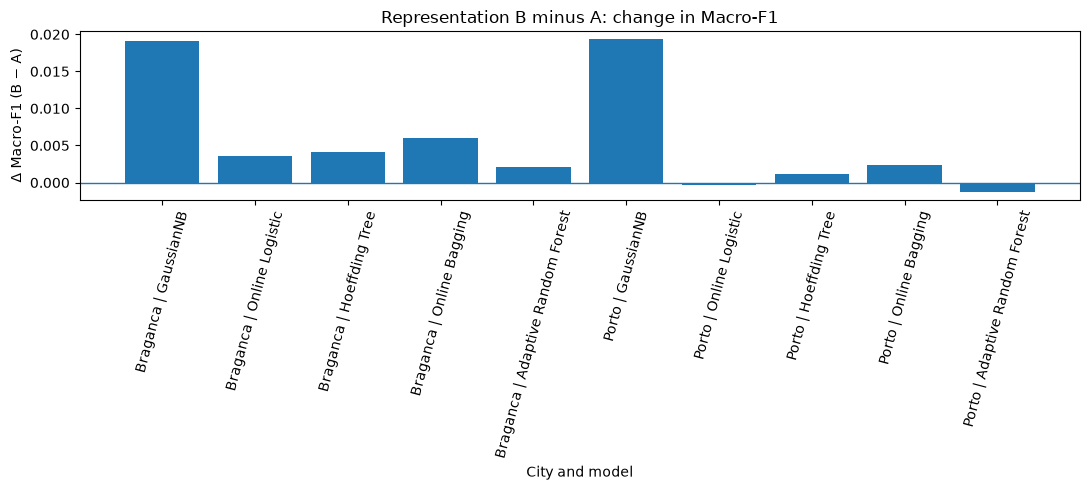

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/representation_delta_macro_f1.png


In [27]:
# Original-analysis candidate 1:
# change in Macro-F1 from Representation A to Representation B.

plot_df = representation_delta.copy()
plot_df["label"] = (
    plot_df["city"].astype(str)
    + " | "
    + plot_df["model"].astype(str).map(MODEL_LABELS)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    plot_df["label"],
    plot_df["delta_macro_f1_B_minus_A"],
)

ax.axhline(0, linewidth=1)
ax.set_title("Representation B minus A: change in Macro-F1")
ax.set_ylabel("Δ Macro-F1 (B − A)")
ax.set_xlabel("City and model")
ax.tick_params(axis="x", rotation=75)

fig.tight_layout()

path = RESULT_FIGURE_DIR / "representation_delta_macro_f1.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path)


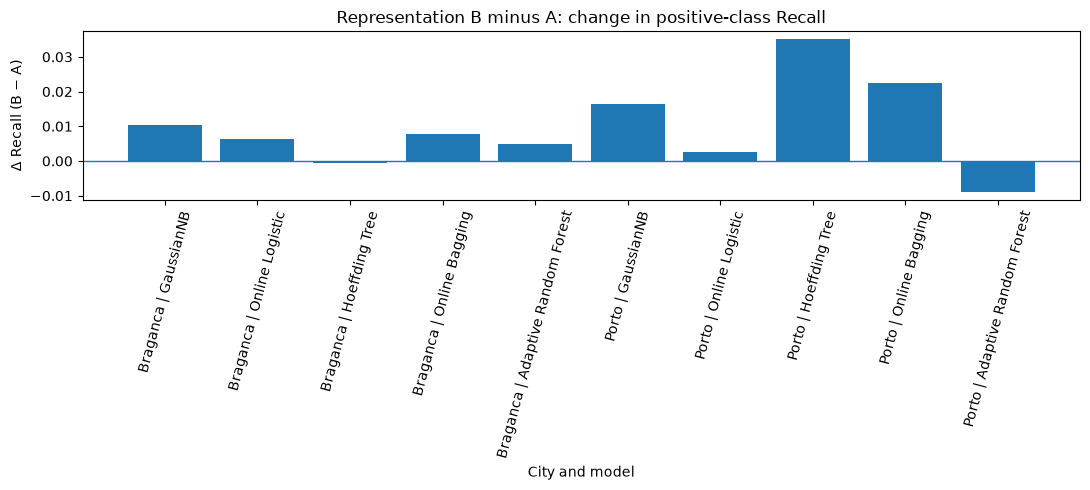

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/representation_delta_recall.png


In [28]:
# Original-analysis candidate 2:
# change in positive-class Recall from Representation A to Representation B.

plot_df = representation_delta.copy()
plot_df["label"] = (
    plot_df["city"].astype(str)
    + " | "
    + plot_df["model"].astype(str).map(MODEL_LABELS)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    plot_df["label"],
    plot_df["delta_recall_positive_B_minus_A"],
)

ax.axhline(0, linewidth=1)
ax.set_title("Representation B minus A: change in positive-class Recall")
ax.set_ylabel("Δ Recall (B − A)")
ax.set_xlabel("City and model")
ax.tick_params(axis="x", rotation=75)

fig.tight_layout()

path = RESULT_FIGURE_DIR / "representation_delta_recall.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path)


## 6. Confusion-matrix evidence and event-detection errors

The complete confusion matrix is required evidence. Instead of producing 20 large heatmaps, this notebook keeps the exact TN / FP / FN / TP counts in a compact table and adds a focused FP-vs-FN plot.




In [29]:
confusion_table = (
    summary[
        [
            "city",
            "representation",
            "model",
            "tn",
            "fp",
            "fn",
            "tp",
        ]
    ]
    .copy()
)

confusion_table["model"] = pd.Categorical(
    confusion_table["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

confusion_table = confusion_table.sort_values(
    ["city", "representation", "model"]
)

display(
    confusion_table
    .set_index(["city", "representation", "model"])
)

confusion_table.to_csv(
    RESULT_TABLE_DIR / "confusion_matrix_counts.csv",
    index=False,
)


tn    fp    fn     tp
city     representation model                                           
Braganca A              gaussian_nb             43193  6558  1232  19145
                        logistic_regression     48476  1275  1172  19205
                        hoeffding_tree          48529  1222  1145  19232
                        online_bagging          48724  1027  1056  19321
                        adaptive_random_forest  48478  1273  1689  18688
         B              gaussian_nb             44225  5526  1023  19354
                        logistic_regression     48553  1198  1045  19332
                        hoeffding_tree          48792   959  1159  19218
                        online_bagging          48914   837   897  19480
                        adaptive_random_forest  48498  1253  1590  18787
Porto    A              gaussian_nb             59453  4986   202   5487
                        logistic_regression     64060   379   734   4955
                        hoeffding_tree          64163   276   587   5102
                        online_bagging          64209   230   569   5120
                        adaptive_random_forest  64044   395  1092   4597
         B              gaussian_nb             60037  4402   109   5580
                        logistic_regression     64035   404   720   4969
                        hoeffding_tree          63958   481   387   5302
                        online_bagging          64115   324   441   5248
                        adaptive_random_forest  64081   358  1143   4546

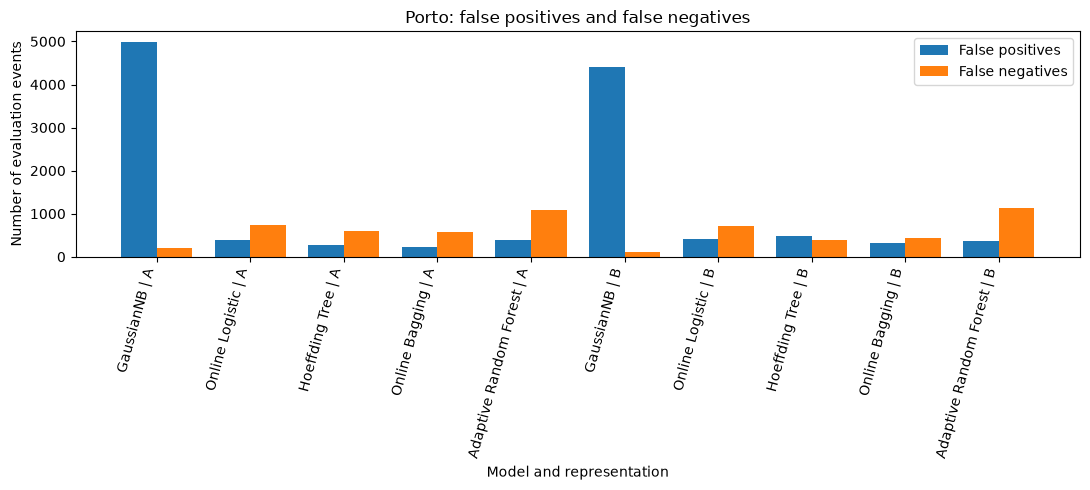

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_fp_fn_comparison.png


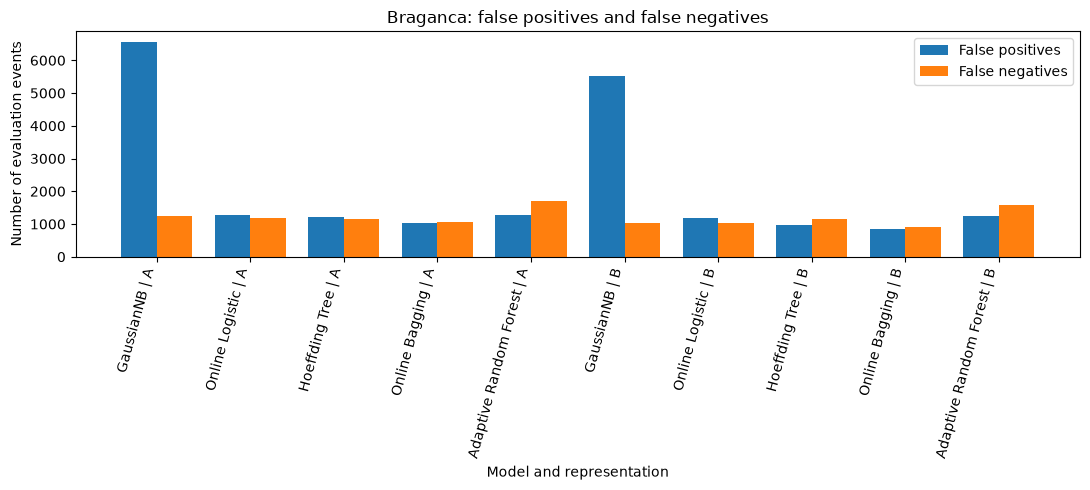

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_fp_fn_comparison.png


In [30]:
for city in CITIES:
    plot_df = confusion_table[
        confusion_table["city"].eq(city)
    ].copy()

    plot_df["label"] = (
        plot_df["model"].astype(str).map(MODEL_LABELS)
        + " | "
        + plot_df["representation"].astype(str)
    )

    x = np.arange(len(plot_df))
    width = 0.38

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.bar(
        x - width / 2,
        plot_df["fp"],
        width,
        label="False positives",
    )

    ax.bar(
        x + width / 2,
        plot_df["fn"],
        width,
        label="False negatives",
    )

    ax.set_title(f"{city}: false positives and false negatives")
    ax.set_ylabel("Number of evaluation events")
    ax.set_xlabel("Model and representation")
    ax.set_xticks(x)
    ax.set_xticklabels(
        plot_df["label"],
        rotation=75,
        ha="right",
    )
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_fp_fn_comparison.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


## 7. Model behaviour over time

Final cumulative scores can hide temporary changes in streaming performance. The histories therefore contain rolling / recent-window metrics collected during prequential evaluation.

The experiment uses a 168-hour recent window (7 days) when available in the saved history.




Available recent-window metrics: ['window_macro_f1', 'window_recall_positive', 'window_precision_positive', 'window_accuracy']


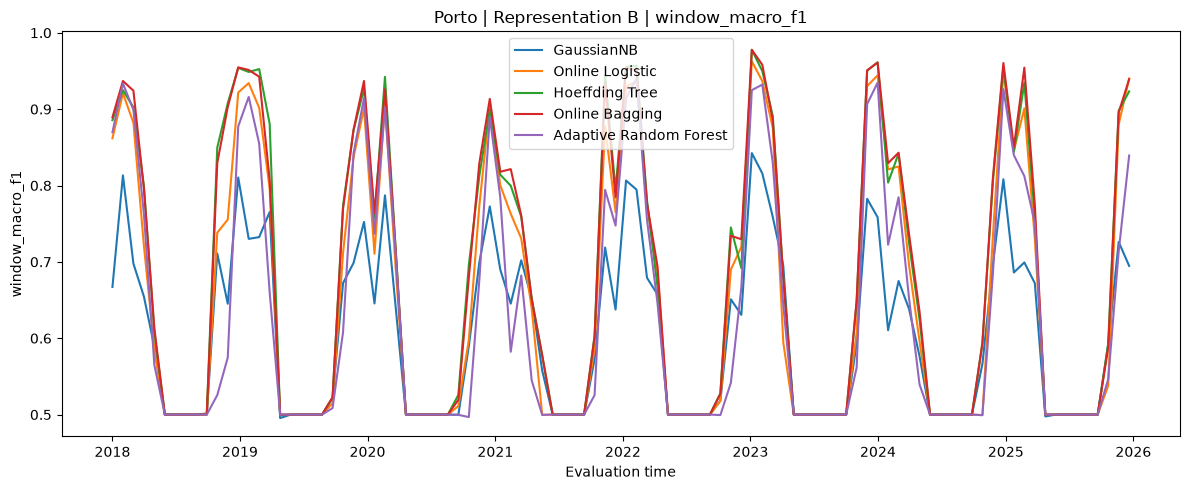

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_b_window_macro_f1_over_time.png


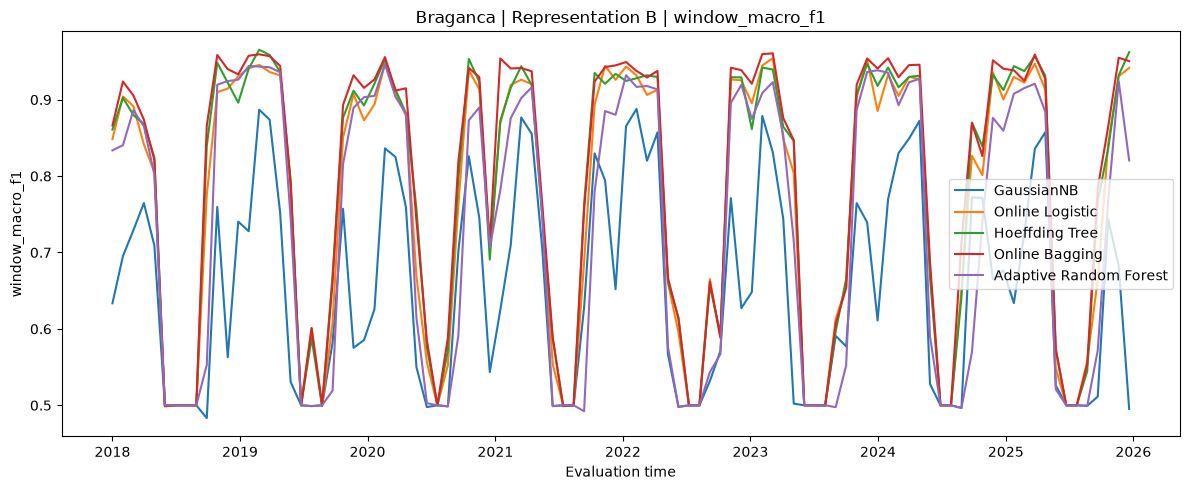

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_b_window_macro_f1_over_time.png


In [31]:
history_metric_candidates = [
    "window_macro_f1",
    "window_recall_positive",
    "window_precision_positive",
    "window_accuracy",
]

available_history_metrics = [
    metric
    for metric in history_metric_candidates
    if metric in history_all.columns
]

print(
    "Available recent-window metrics:",
    available_history_metrics,
)


def plot_window_metric(
    city,
    representation,
    metric,
    resample_rule="30D",
):
    if metric not in history_all.columns:
        print(
            f"Skipping {metric}: column not available "
            "in the saved histories."
        )
        return

    subset = history_all[
        history_all["city"].eq(city)
        & history_all["representation"].eq(representation)
    ].copy()

    fig, ax = plt.subplots(figsize=(12, 5))

    for model in MODEL_NAMES:
        model_df = subset[
            subset["model"].eq(model)
        ].copy()

        if model_df.empty:
            continue

        model_df = (
            model_df
            .sort_values("timestamp")
            .set_index("timestamp")
        )

        # Monthly aggregation is only for visual readability.
        # The underlying hourly evaluation history remains unchanged.
        series = (
            model_df[metric]
            .resample(resample_rule)
            .mean()
        )

        ax.plot(
            series.index,
            series.values,
            label=MODEL_LABELS.get(model, model),
        )

    ax.set_title(
        f"{city} | Representation {representation} | {metric}"
    )
    ax.set_ylabel(metric)
    ax.set_xlabel("Evaluation time")
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_{representation.lower()}_{metric}_over_time.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


for city in CITIES:
    plot_window_metric(
        city=city,
        representation="B",
        metric="window_macro_f1",
    )


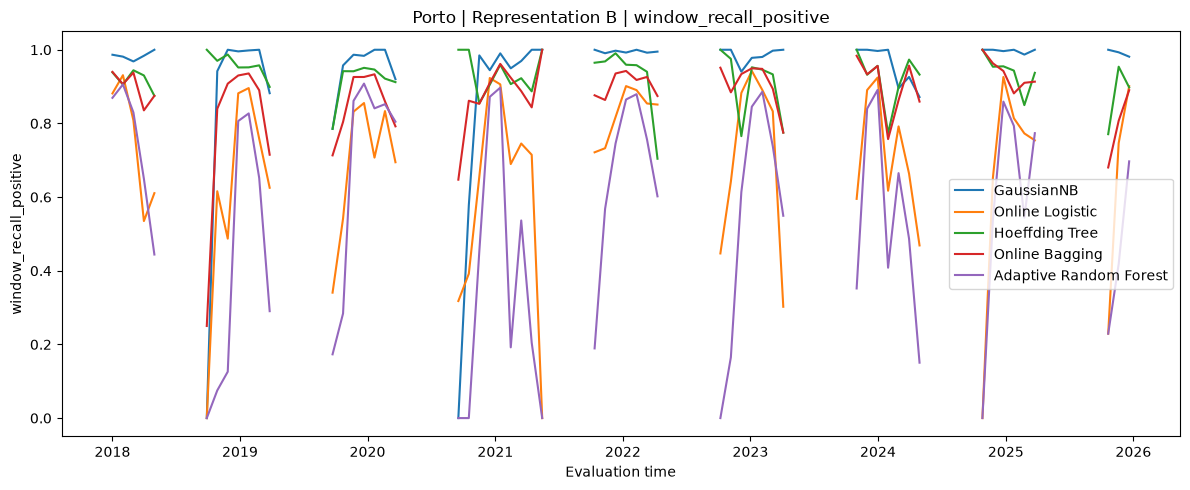

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_b_window_recall_positive_over_time.png


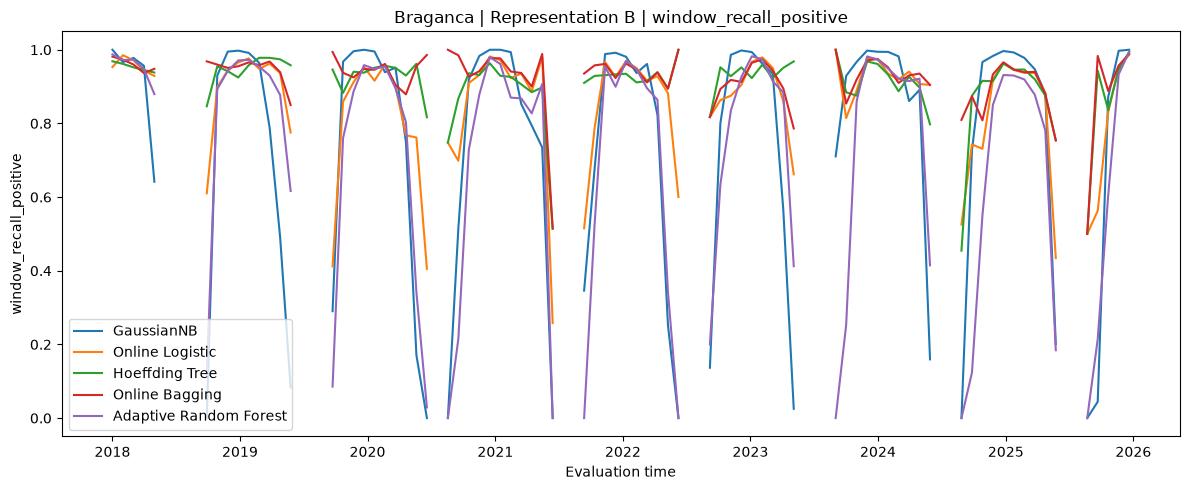

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_b_window_recall_positive_over_time.png


In [32]:
# Optional additional temporal evidence:
# positive-class Recall over time, if this metric was stored in the histories.

if "window_recall_positive" in history_all.columns:
    for city in CITIES:
        plot_window_metric(
            city=city,
            representation="B",
            metric="window_recall_positive",
        )
else:
    print(
        "window_recall_positive is not present in the saved history files. "
        "No additional Recall-over-time plot was generated."
    )


## 8. Computational evidence and cost–performance view


The first table reports the exact measured costs from the official runs. The scatter plot places computational cost and predictive performance in the same visual space.




In [33]:
cost_table = (
    summary[
        [
            "city",
            "representation",
            "model",
            "prediction_ms_per_event",
            "update_ms_per_event",
        ]
    ]
    .copy()
)

cost_table["model"] = pd.Categorical(
    cost_table["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

cost_table = cost_table.sort_values(
    ["city", "representation", "model"]
)

display(
    cost_table
    .set_index(["city", "representation", "model"])
    .round(6)
)

cost_table.to_csv(
    RESULT_TABLE_DIR / "computational_cost.csv",
    index=False,
)


prediction_ms_per_event  update_ms_per_event
city     representation model                                                               
Braganca A              gaussian_nb                            0.071175             0.004755
                        logistic_regression                    0.003701             0.010901
                        hoeffding_tree                         0.005988             0.025250
                        online_bagging                         0.063146             0.251744
                        adaptive_random_forest                 0.071112             0.435632
         B              gaussian_nb                            0.079684             0.006269
                        logistic_regression                    0.004449             0.014078
                        hoeffding_tree                         0.007112             0.031418
                        online_bagging                         0.066910             0.317133
                        adaptive_random_forest                 0.071308             0.516993
Porto    A              gaussian_nb                            0.073504             0.004802
                        logistic_regression                    0.003784             0.011108
                        hoeffding_tree                         0.005363             0.025891
                        online_bagging                         0.055684             0.245563
                        adaptive_random_forest                 0.064156             0.365039
         B              gaussian_nb                            0.076980             0.005999
                        logistic_regression                    0.004456             0.014342
                        hoeffding_tree                         0.005874             0.030294
                        online_bagging                         0.057078             0.298370
                        adaptive_random_forest                 0.065708             0.423419

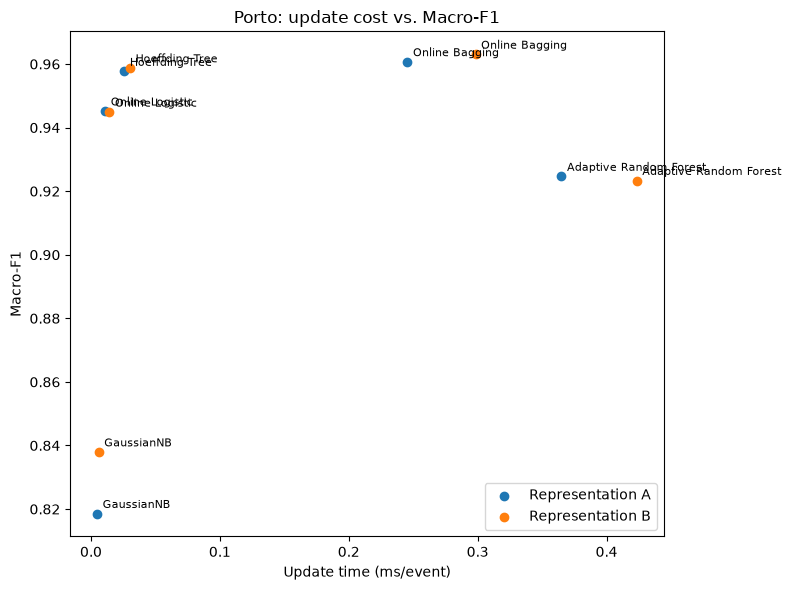

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_cost_vs_macro_f1.png


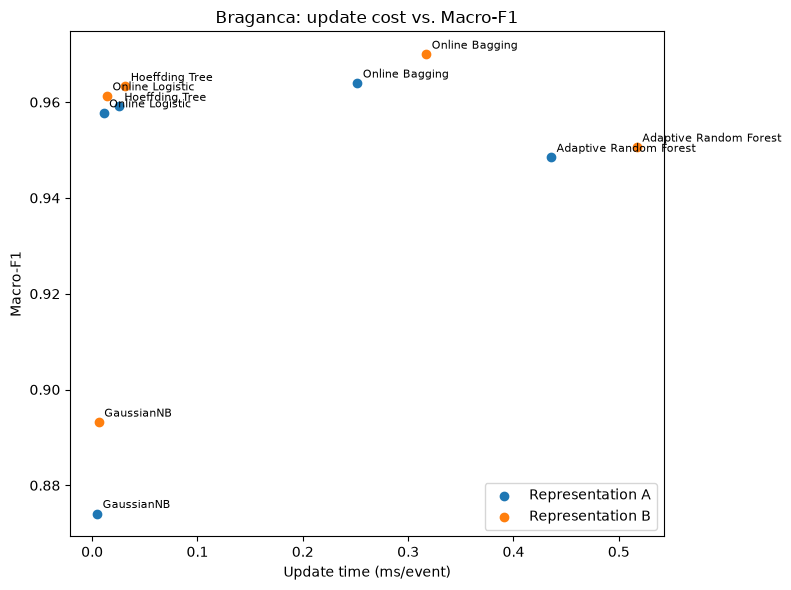

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_cost_vs_macro_f1.png


In [34]:
for city in CITIES:
    plot_df = summary[
        summary["city"].eq(city)
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 6))

    for representation in REPRESENTATIONS:
        rep_df = plot_df[
            plot_df["representation"].eq(representation)
        ]

        ax.scatter(
            rep_df["update_ms_per_event"],
            rep_df["macro_f1"],
            label=f"Representation {representation}",
        )

        for _, row in rep_df.iterrows():
            ax.annotate(
                MODEL_LABELS.get(row["model"], row["model"]),
                (
                    row["update_ms_per_event"],
                    row["macro_f1"],
                ),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )

    ax.set_title(
        f"{city}: update cost vs. Macro-F1"
    )
    ax.set_xlabel("Update time (ms/event)")
    ax.set_ylabel("Macro-F1")
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_cost_vs_macro_f1.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


## 9. Persistence baseline

Because the target is hourly Cold Stress and the previous temperature / previous state is highly informative, a persistence baseline is useful contextual evidence.

The baseline is:

\[
\hat{y}_t = y_{t-1}
\]

It is **not** one of the five mandatory learners and does not replace any official experiment. It is only a reference that helps contextualise the difficulty of the hourly prediction task.




In [35]:
from src.run_experiments import prepare_experiment_data


def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    accuracy = (tp + tn) / len(y_true)

    precision_positive = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall_positive = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision_negative = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    recall_negative = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    f1_positive = (
        2
        * precision_positive
        * recall_positive
        / (precision_positive + recall_positive)
        if (
            np.isfinite(precision_positive)
            and np.isfinite(recall_positive)
            and (precision_positive + recall_positive) > 0
        )
        else np.nan
    )

    f1_negative = (
        2
        * precision_negative
        * recall_negative
        / (precision_negative + recall_negative)
        if (
            np.isfinite(precision_negative)
            and np.isfinite(recall_negative)
            and (precision_negative + recall_negative) > 0
        )
        else np.nan
    )

    macro_f1 = np.nanmean(
        [f1_negative, f1_positive]
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "precision_positive": precision_positive,
        "recall_positive": recall_positive,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


city_streams, threshold = prepare_experiment_data()

baseline_rows = []

for city in CITIES:
    warmup = city_streams[city]["warmup"]
    evaluation = city_streams[city]["evaluation"]

    y_true = (
        evaluation[TARGET_COLUMN]
        .astype(int)
        .reset_index(drop=True)
    )

    previous_state = np.empty(
        len(evaluation),
        dtype=int,
    )

    previous_state[0] = int(
        warmup[TARGET_COLUMN].iloc[-1]
    )

    previous_state[1:] = (
        y_true.iloc[:-1]
        .to_numpy(dtype=int)
    )

    metrics = binary_metrics(
        y_true,
        previous_state,
    )

    baseline_rows.append(
        {
            "city": city,
            "baseline": "persistence_y_t_minus_1",
            **metrics,
        }
    )

persistence_baseline = pd.DataFrame(
    baseline_rows
)

display(
    persistence_baseline
    .set_index(["city", "baseline"])
    .round(4)
)

persistence_baseline.to_csv(
    RESULT_TABLE_DIR / "persistence_baseline.csv",
    index=False,
)


,,accuracy,macro_f1,precision_positive,recall_positive,tn,fp,fn,tp
city,baseline,,,,,,,,
Porto,persistence_y_t_minus_1,0.9829,0.9426,0.8945,0.8944,63839,600,601,5088
Braganca,persistence_y_t_minus_1,0.9636,0.9558,0.9373,0.9373,48473,1278,1278,19099


## 10. Transition diagnostics

Persistence is strongest when the target remains unchanged. Therefore, a useful supplementary diagnostic is to inspect the hours where the Cold Stress state changes:

- `0 → 1`: Cold Stress onset
- `1 → 0`: Cold Stress ending




In [36]:
transition_rows = []

for path in history_paths:
    history = pd.read_csv(path)

    timestamp_col = (
        "timestamp"
        if "timestamp" in history.columns
        else "timestamp_utc"
    )

    history[timestamp_col] = pd.to_datetime(
        history[timestamp_col],
        utc=True,
    )

    history = history.sort_values(
        timestamp_col
    ).reset_index(drop=True)

    required = {
        "city",
        "representation",
        "model",
        "y_true",
        "y_pred",
    }

    if not required.issubset(history.columns):
        raise ValueError(
            f"{path.name} is missing metadata or prediction columns."
        )

    city = history["city"].iloc[0]
    representation = history["representation"].iloc[0]
    model = history["model"].iloc[0]

    y_true = history["y_true"].astype(int)
    y_pred = history["y_pred"].astype(int)

    previous = y_true.shift(1)

    # The first evaluation event uses the final warm-up state as y_(t-1).
    previous.iloc[0] = int(
        city_streams[city]["warmup"][TARGET_COLUMN].iloc[-1]
    )

    previous = previous.astype(int)

    transition_mask = y_true.ne(previous)
    onset_mask = previous.eq(0) & y_true.eq(1)
    ending_mask = previous.eq(1) & y_true.eq(0)

    transition_accuracy = (
        y_pred[transition_mask]
        .eq(y_true[transition_mask])
        .mean()
    )

    onset_detection_rate = (
        y_pred[onset_mask]
        .eq(1)
        .mean()
    )

    ending_detection_rate = (
        y_pred[ending_mask]
        .eq(0)
        .mean()
    )

    transition_rows.append(
        {
            "city": city,
            "representation": representation,
            "model": model,
            "transition_events": int(transition_mask.sum()),
            "cold_onsets_0_to_1": int(onset_mask.sum()),
            "cold_endings_1_to_0": int(ending_mask.sum()),
            "transition_accuracy": transition_accuracy,
            "onset_detection_rate": onset_detection_rate,
            "ending_detection_rate": ending_detection_rate,
        }
    )

transition_diagnostics = pd.DataFrame(
    transition_rows
)

transition_diagnostics["model"] = pd.Categorical(
    transition_diagnostics["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

transition_diagnostics = transition_diagnostics.sort_values(
    ["city", "representation", "model"]
)

display(
    transition_diagnostics
    .set_index(["city", "representation", "model"])
    .round(4)
)

transition_diagnostics.to_csv(
    RESULT_TABLE_DIR / "transition_diagnostics.csv",
    index=False,
)


transition_events  cold_onsets_0_to_1  cold_endings_1_to_0  transition_accuracy  onset_detection_rate  \
city     representation model                                                                                                                           
Braganca A              gaussian_nb                          2556                1278                 1278               0.4969                0.7183   
                        logistic_regression                  2556                1278                 1278               0.3345                0.3271   
                        hoeffding_tree                       2556                1278                 1278               0.3662                0.3740   
                        online_bagging                       2556                1278                 1278               0.3865                0.3576   
                        adaptive_random_forest               2556                1278                 1278               0.2183                0.1831   
         B              gaussian_nb                          2556                1278                 1278               0.4472                0.6690   
                        logistic_regression                  2556                1278                 1278               0.4491                0.4366   
                        hoeffding_tree                       2556                1278                 1278               0.5207                0.4413   
                        online_bagging                       2556                1278                 1278               0.4949                0.4390   
                        adaptive_random_forest               2556                1278                 1278               0.3212                0.3020   
Porto    A              gaussian_nb                          1201                 601                  600               0.6711                0.9168   
                        logistic_regression                  1201                 601                  600               0.4263                0.2579   
                        hoeffding_tree                       1201                 601                  600               0.4513                0.2346   
                        online_bagging                       1201                 601                  600               0.4555                0.2146   
                        adaptive_random_forest               1201                 601                  600               0.3214                0.1597   
         B              gaussian_nb                          1201                 601                  600               0.6261                0.9468   
                        logistic_regression                  1201                 601                  600               0.4138                0.2429   
                        hoeffding_tree                       1201                 601                  600               0.6137                0.5657   
                        online_bagging                       1201                 601                  600               0.5087                0.3760   
                        adaptive_random_forest               1201                 601                  600               0.3047                0.1215   

                                                ending_detection_rate  
city     representation model                                          
Braganca A              gaussian_nb                            0.2754  
                        logistic_regression                    0.3419  
                        hoeffding_tree                         0.3584  
                        online_bagging                         0.4155  
                        adaptive_random_forest                 0.2535  
         B              gaussian_nb                            0.2254  
                        logistic_regression                    0.4617  
                        hoeffding

In [37]:
print("Generated result tables:")
for path in sorted(RESULT_TABLE_DIR.glob("*.csv")):
    print(" -", path.relative_to(PROJECT_ROOT))

print("\nGenerated result figures:")
for path in sorted(RESULT_FIGURE_DIR.glob("*.png")):
    print(" -", path.relative_to(PROJECT_ROOT))


Generated result tables:
 - outputs/results_tables/braganca_predictive_performance.csv
 - outputs/results_tables/computational_cost.csv
 - outputs/results_tables/confusion_matrix_counts.csv
 - outputs/results_tables/joint_vs_individual.csv
 - outputs/results_tables/joint_vs_individual_confusion.csv
 - outputs/results_tables/joint_vs_individual_cost.csv
 - outputs/results_tables/persistence_baseline.csv
 - outputs/results_tables/porto_predictive_performance.csv
 - outputs/results_tables/representation_B_minus_A_deltas.csv
 - outputs/results_tables/transition_diagnostics.csv

Generated result figures:
 - outputs/results_figures/braganca_b_online_bagging_joint_vs_individual_recall.png
 - outputs/results_figures/braganca_b_window_macro_f1_over_time.png
 - outputs/results_figures/braganca_b_window_recall_positive_over_time.png
 - outputs/results_figures/braganca_cost_vs_macro_f1.png
 - outputs/results_figures/braganca_fp_fn_comparison.png
 - outputs/results_figures/porto_b_online_bagging_jo

Experiment validation
The mechanical audit confirmed that the city-specific experimental outputs were internally consistent with the predefined design. All 20 expected city–representation–model combinations were present, no duplicated runs or cold starts were detected, the confusion-matrix totals matched the number of evaluation observations, and the frozen experimental settings remained consistent across runs. Each city-specific run evaluated 70,128 hourly observations. The updated experiments used the same eleven base predictors for Porto and Bragança; snowfall was excluded from predictive modelling in both cities. These checks support the comparability of the city-specific prequential evaluation histories.
Predictive performance
Overall, the streaming classifiers achieved strong predictive performance, although the results should not be interpreted through Accuracy alone. Most models obtained high Accuracy values, indicating that the majority of hourly Cold Stress states were classified correctly. Gaussian Naive Bayes was the main exception, particularly in Bragança, where its Accuracy was noticeably lower than that of the other learners.

Positive-class Recall was generally high across the experiments, meaning that most actual Cold Stress events were successfully detected. This metric is particularly relevant in the present operational context because a false negative corresponds to a Cold Stress event that the monitoring system fails to identify. Precision was also high for most models, indicating that predictions of Cold Stress were usually correct. However, Gaussian Naive Bayes behaved differently, especially in Porto, where its very high Recall was accompanied by substantially lower Precision. Its ability to detect almost all Cold Stress events therefore came at the cost of generating considerably more false alarms.

The resulting Macro-F1 scores were also high for most models, showing that the classifiers generally maintained a good balance between performance on the Cold Stress and non-Cold-Stress classes rather than simply exploiting the majority class. Online Bagging with Representation B achieved the highest city-specific Macro-F1 in both Porto (0.96307) and Bragança (0.96999) under the implemented selection criterion.

The comparison between the cities requires some nuance. Accuracy was higher in Porto for every corresponding model–representation configuration, while positive-class Recall was higher in Bragança for eight of the ten configurations. Precision was also generally strong in Bragança. One plausible factor is the difference in target prevalence: Cold Stress represents approximately 29.1% of the evaluation observations in Bragança but only about 8.1% in Porto. The models therefore receive substantially more positive examples in the Bragança stream, whereas the stronger class imbalance in Porto makes high overall Accuracy easier to obtain through correct classification of the dominant non-Cold-Stress class.
Representation A versus Representation B
The comparison between Representation A and Representation B shows that the additional temporal context introduced in Representation B does not produce a dramatic improvement in final predictive performance for every classifier.

The effect differs across cities. In Bragança, Representation B improved Accuracy and Macro-F1 for all five algorithms; positive-class Recall increased for four of them, with Hoeffding Tree as the exception. In Porto, Representation B improved Macro-F1 for three of the five algorithms (Gaussian Naive Bayes, Hoeffding Tree and Online Bagging) and Recall for four; its effects on Accuracy and Precision were mixed. Adaptive Random Forest showed a small reduction in Macro-F1 and Recall in Porto, but modest improvements in Bragança. Therefore, the gains from temporal context are model- and city-dependent.

A plausible explanation is that an informative temporal predictor is already available in Representation A: the previous hourly temperature, \(T_{t-1}\). Because hourly temperature is highly persistent, this lag already contains substantial information about whether the next observation will fall below the Cold Stress threshold. The additional delta, rolling mean, rolling standard deviation and recent-condition features included in Representation B therefore provide useful temporal information in some cases, but their incremental contribution may be limited relative to the information already contained in the most recent temperature observation.

This suggests that the comparison between A and B is less about a dramatic change in overall predictive capability and more about whether additional temporal context can improve specific aspects of event detection, such as Recall, for particular learners.
Cold Stress detection and false negatives
If the objective is defined strictly as maximising Cold Stress Recall and minimising false negatives, different models emerge in the two cities.

In Porto, Gaussian Naive Bayes with Representation B achieved the highest positive-class Recall (0.98084), with 109 false negatives. However, this high sensitivity was accompanied by much lower Precision (0.55901) and 4,402 false positives. Thus, selecting a model solely for Recall would involve a substantial number of false alarms. Among the other models, Hoeffding Tree B reached a Recall of 0.93197 and Macro-F1 of 0.95880, with an update cost of 0.03029 ms/event. Online Bagging B reached the highest Porto Macro-F1 (0.96307), with Recall 0.92248, Precision 0.94185, 441 false negatives and an update cost of 0.29837 ms/event. Therefore, Online Bagging B is the selected Porto model under the predefined Macro-F1-first rule; Hoeffding Tree B remains a lower-cost alternative with a higher positive-class Recall. These are different selection priorities and should not be conflated.

In Bragança, Online Bagging with Representation B achieved the highest positive-class Recall (0.95598) and the fewest false negatives (897) among the city-specific configurations. Its Precision was 0.95880, its Macro-F1 was 0.96999, and its false-positive count was 837. It was also the top-ranked Bragança configuration by Macro-F1.

These results illustrate why Recall cannot be interpreted independently from Precision and the confusion matrix. Maximising Recall alone may be desirable when missing a Cold Stress event is particularly costly, but the operational consequences of false alarms must also be considered.
Recent-window behaviour over time
The temporal performance plots use a rolling evaluation window of 168 observations (one week of hourly data). They therefore describe recent model behaviour rather than cumulative performance over the complete 2018–2025 evaluation period.

A noticeable characteristic of these plots is that Macro-F1 can fall sharply during periods with few or no Cold Stress events. This behaviour is partly a consequence of the metric definition rather than necessarily evidence of a sudden deterioration of the classifier.

Macro-F1 calculates the F1-score independently for each class and then gives both classes equal weight. When a 168-hour window contains no positive Cold Stress observations, the implemented metric assigns the positive class an F1-score of zero. If the model simultaneously classifies the non-Cold-Stress class almost perfectly, its negative-class F1 may remain close to 1. The resulting Macro-F1 is consequently close to:
\[
\frac{1 + 0}{2} = 0.5.
\]
Therefore, temporary drops towards approximately 0.5 should not automatically be interpreted as a collapse in predictive ability. They may instead reflect periods in which one class is absent from the recent evaluation window. This effect is expected to be more visible in Porto because Cold Stress events are substantially less frequent there.

The rolling plots are nevertheless useful because they show that final cumulative metrics alone do not fully describe the behaviour of an online classifier. Stream performance varies over time as the local class distribution and weather conditions change.
Computational performance
Prediction latency was low for all city-specific models, remaining below 0.08 ms per event in the recorded runs. At an hourly sampling frequency, these prediction costs are small relative to the time between observations.

Update times showed clearer differences between algorithms. All city-specific update costs remained below 0.6 ms per event, but update cost generally increased with model complexity. Simpler incremental learners required relatively little computation to incorporate each new observation, whereas ensemble approaches such as Online Bagging and Adaptive Random Forest required substantially more update time because several component models must be updated for each incoming event.

The Hoeffding Tree provides an efficiency-oriented point of comparison: it achieves high Macro-F1 while maintaining a substantially lower update cost than Online Bagging. In Porto, for Representation B, Hoeffding Tree required 0.03029 ms/event to update, compared with 0.29837 ms/event for Online Bagging. The corresponding Macro-F1 values were 0.95880 and 0.96307, respectively. These results describe a predictive–computational trade-off; they do not establish a single universally optimal model without an explicit operational cost criterion.

For this reason, the Hoeffding Tree can be considered a strong efficiency-oriented candidate when computational simplicity and continuous low-cost updating are important. This should be described as a favourable trade-off rather than as a mathematically defined “best ratio”, unless a formal cost-performance ratio is explicitly introduced.
Persistence baseline and difficulty of the hourly prediction problem
The persistence baseline provides important context for understanding the apparently very high predictive scores obtained by the machine-learning models.

The baseline makes the simple prediction:
\[
\hat{y}_t = y_{t-1},
\]
meaning that it assumes the current Cold Stress state will be identical to the state observed one hour earlier. Despite requiring no learning algorithm, this rule achieved an Accuracy of 98.29% in Porto and 96.36% in Bragança.

This demonstrates that the hourly target has very strong temporal persistence. Temperature normally changes gradually from one hour to the next, so if the temperature is already below the Cold Stress threshold at one observation, there is a high probability that it will remain below the threshold during the following observation. Similarly, a non-Cold-Stress state usually remains unchanged over consecutive hours.

The machine-learning models do not directly receive \(y_{t-1}\) as their principal predictor in Representation A. However, Representation A contains \(T_{t-1}\), and the previous Cold Stress state is determined by whether \(T_{t-1}\) lies below the frozen threshold. The strong persistence demonstrated by the baseline therefore helps explain why previous temperature is such a powerful predictor and why very high overall Accuracy can be achieved in this hourly forecasting setup.

Consequently, the absolute level of Accuracy should not be viewed as the most challenging aspect of the task. A more demanding problem occurs when the Cold Stress state changes between consecutive observations.
Transition analysis
The transition analysis isolates the observations for which:
\[
y_t \neq y_{t-1}.
\]
These correspond to the onset of Cold Stress (0 → 1) and the end of a Cold Stress period (1 → 0). They are particularly informative because the persistence baseline necessarily fails on every such observation: copying the previous state cannot correctly predict a state transition.

The transition results therefore provide a stricter test of whether the classifiers can detect changes in weather regime rather than simply exploiting hourly persistence.

According to the updated transition diagnostic, Gaussian Naive Bayes A achieved the highest transition accuracy in Porto (0.67111, across 1,201 transitions), while Hoeffding Tree B achieved the highest transition accuracy in Bragança (0.52074, across 2,556 transitions). For comparison, Online Bagging B achieved transition accuracy of 0.50874 in Porto and 0.49491 in Bragança. The model that maximises overall Macro-F1 is therefore not necessarily the one with the highest transition accuracy.

This transition-focused analysis is particularly useful for contextualising the very high global Accuracy values. A classifier may obtain excellent overall performance because most consecutive observations remain in the same state, while transition events represent the more difficult subset of the stream. Evaluating these cases separately therefore provides additional information about the models' ability to identify changes rather than simply maintain the previous classification.
Unified learning experiment: factual results
The city-specific selection rule (highest Macro-F1, then positive-class Recall and computational cost as tie-breakers) selected Online Bagging B in both cities. After duplicate configurations were removed, one unified experiment was run using a shared Online Bagging B classifier. The model was updated with observations from both cities, while temporal feature states and evaluation metrics remained city-specific.
| City | Protocol | Accuracy | Macro-F1 | Precision (+) | Recall (+) | FP | FN |
|---|---|---:|---:|---:|---:|---:|---:|
| Porto | Individual | 0.98909 | 0.96307 | 0.94185 | 0.92248 | 324 | 441 |
| Porto | Joint | 0.98948 | 0.96447 | 0.94150 | 0.92793 | 328 | 410 |
| Bragança | Individual | 0.97527 | 0.96999 | 0.95880 | 0.95598 | 837 | 897 |
| Bragança | Joint | 0.97663 | 0.97157 | 0.96441 | 0.95480 | 718 | 921 |


Relative to the corresponding city-specific Online Bagging B model, the joint configuration had a Macro-F1 difference of +0.00140 in Porto and +0.00159 in Bragança. For the positive class, Porto had 31 fewer false negatives and 4 more false positives, whereas Bragança had 24 more false negatives and 119 fewer false positives.

The unified model received 35,040 warm-up updates, compared with 17,520 updates for each city-specific model. Both protocols were evaluated on the same 70,128 hourly observations per city. Because the configurations were selected using performance on the 2018–2025 evaluation period, comparisons over that same period should be treated as exploratory, not as independent confirmatory evidence of superiority.

## 11. Joint vs. Individual Incremental Learning

In [38]:

# seleção best models 
from config.experiment import BASE_FEATURES
from src.features import get_feature_columns

assert BASE_FEATURES[CITY_A] == BASE_FEATURES[CITY_B]
assert len(BASE_FEATURES[CITY_A]) == 11

for rep in REPRESENTATIONS:
    assert (
        get_feature_columns(CITY_A, rep)
        == get_feature_columns(CITY_B, rep)
    )

keys = ["city", "representation", "model"]

metrics = [
    "accuracy",
    "macro_f1",
    "precision_positive",
    "recall_positive",
]

selection_table = summary.copy()

selection_table["total_ms_per_event"] = (
    selection_table["prediction_ms_per_event"]
    + selection_table["update_ms_per_event"]
)

best_per_city = (
    selection_table
    .sort_values(
        [
            "city",
            "macro_f1",
            "recall_positive",
            "total_ms_per_event",
            "model",
            "representation",
        ],
        ascending=[True, False, False, True, True, True],
    )
    .drop_duplicates("city")
    .reset_index(drop=True)
)

display(
    best_per_city[
        ["city", "model", "representation",
         "macro_f1", "recall_positive",
         "total_ms_per_event"]
    ]
)

selected_configs = list(
    best_per_city[["model", "representation"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

print("Selected joint configurations:", selected_configs)


# CARREGAR RESULTADOS DO MODELO CONJUNTO

JOINT_DIR = PROJECT_ROOT / "results" / "joint"

joint_summary = pd.read_csv(
    JOINT_DIR / "summaries" / "joint_experiment_summary.csv"
)

with (
    JOINT_DIR / "joint_manifest.json"
).open("r", encoding="utf-8") as file:
    joint_manifest = json.load(file)


# VALIDAR AS CONFIGURACOES EXECUTADAS

manifest_configs = {
    (item["model"], item["representation"])
    for item in joint_manifest["joint_configurations"]
}

assert manifest_configs == set(selected_configs)

expected_keys = {
    (city, rep, model)
    for city in CITIES
    for model, rep in selected_configs
}

actual_keys = set(
    joint_summary[keys].itertuples(index=False, name=None)
)

assert actual_keys == expected_keys
assert len(joint_summary) == len(expected_keys)
assert not joint_summary.duplicated(keys).any()
assert joint_summary["protocol"].eq("joint").all()

# Verificar o mesmo periodo de avaliacao.
coverage = summary[
    keys + ["evaluation_rows"]
].merge(
    joint_summary[keys + ["evaluation_rows"]],
    on=keys,
    suffixes=("_individual", "_joint"),
    validate="one_to_one",
)

assert len(coverage) == len(expected_keys)
assert (
    coverage["evaluation_rows_individual"]
    == coverage["evaluation_rows_joint"]
).all()

# Verificar o mesmo threshold.
assert joint_summary["cold_threshold"].nunique() == 1
assert np.isclose(
    joint_summary["cold_threshold"].iloc[0],
    summary["cold_threshold"].iloc[0],
)


# COMPARACAO PREDITIVA

comparison = summary[keys + metrics].merge(
    joint_summary[keys + metrics],
    on=keys,
    suffixes=("_individual", "_joint"),
    validate="one_to_one",
)

assert len(comparison) == len(expected_keys)

for metric in metrics:
    comparison[f"delta_{metric}"] = (
        comparison[f"{metric}_joint"]
        - comparison[f"{metric}_individual"]
    )

comparison = comparison.sort_values(keys).reset_index(drop=True)

display(comparison.round(4))

comparison.to_csv(
    RESULT_TABLE_DIR / "joint_vs_individual.csv",
    index=False,
)


,city,model,representation,macro_f1,recall_positive,total_ms_per_event
0,Braganca,online_bagging,B,0.969987,0.955980,0.384043
1,Porto,online_bagging,B,0.963068,0.922482,0.355447


Selected joint configurations: [('online_bagging', 'B')]


,city,representation,model,accuracy_individual,macro_f1_individual,precision_positive_individual,recall_positive_individual,accuracy_joint,macro_f1_joint,precision_positive_joint,recall_positive_joint,delta_accuracy,delta_macro_f1,delta_precision_positive,delta_recall_positive
0,Braganca,B,online_bagging,0.9753,0.9700,0.9588,0.9560,0.9766,0.9716,0.9644,0.9548,0.0014,0.0016,0.0056,-0.0012
1,Porto,B,online_bagging,0.9891,0.9631,0.9419,0.9225,0.9895,0.9645,0.9415,0.9279,0.0004,0.0014,-0.0004,0.0054


In [39]:

error_metrics = ["tn", "fp", "fn", "tp"]

error_comparison = summary[
    keys + error_metrics
].merge(
    joint_summary[keys + error_metrics],
    on=keys,
    suffixes=("_individual", "_joint"),
    validate="one_to_one",
)

assert len(error_comparison) == len(expected_keys)

for metric in ["fp", "fn"]:
    error_comparison[f"delta_{metric}"] = (
        error_comparison[f"{metric}_joint"]
        - error_comparison[f"{metric}_individual"]
    )

error_comparison = (
    error_comparison.sort_values(keys)
    .reset_index(drop=True)
)

display(error_comparison)

error_comparison.to_csv(
    RESULT_TABLE_DIR / "joint_vs_individual_confusion.csv",
    index=False,
)


,city,representation,model,tn_individual,fp_individual,fn_individual,tp_individual,tn_joint,fp_joint,fn_joint,tp_joint,delta_fp,delta_fn
0,Braganca,B,online_bagging,48914,837,897,19480,49033,718,921,19456,-119,24
1,Porto,B,online_bagging,64115,324,441,5248,64111,328,410,5279,4,-31


In [40]:
cost_metrics = [
    "prediction_ms_per_event",
    "update_ms_per_event",
]

cost_comparison = summary[keys + cost_metrics].merge(
    joint_summary[keys + cost_metrics],
    on=keys,
    suffixes=("_individual", "_joint"),
    validate="one_to_one",
)

for protocol in ("individual", "joint"):
    cost_comparison[f"total_ms_{protocol}"] = (
        cost_comparison[
            f"prediction_ms_per_event_{protocol}"
        ]
        + cost_comparison[
            f"update_ms_per_event_{protocol}"
        ]
    )

display(cost_comparison.round(4))

cost_comparison.to_csv(
    RESULT_TABLE_DIR / "joint_vs_individual_cost.csv",
    index=False,
)

,city,representation,model,prediction_ms_per_event_individual,update_ms_per_event_individual,prediction_ms_per_event_joint,update_ms_per_event_joint,total_ms_individual,total_ms_joint
0,Porto,B,online_bagging,0.0571,0.2984,0.0607,0.3036,0.3554,0.3643
1,Braganca,B,online_bagging,0.0669,0.3171,0.0607,0.3059,0.3840,0.3666


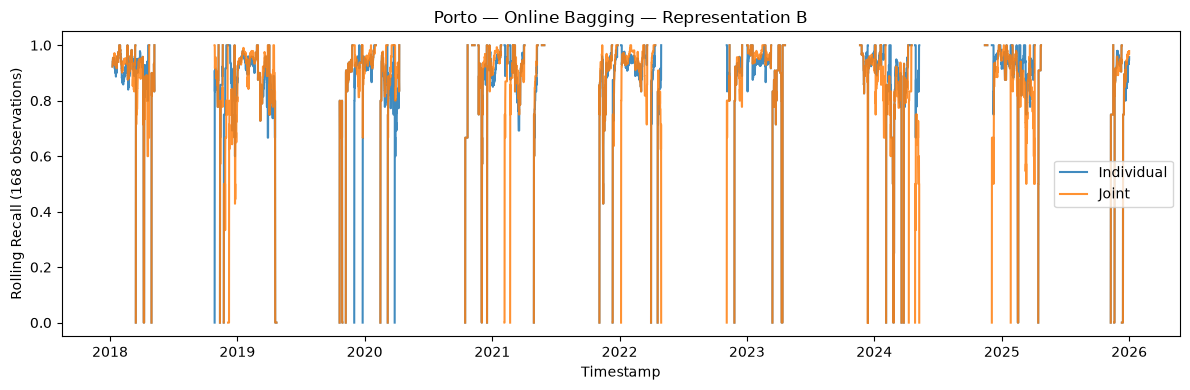

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_b_online_bagging_joint_vs_individual_recall.png


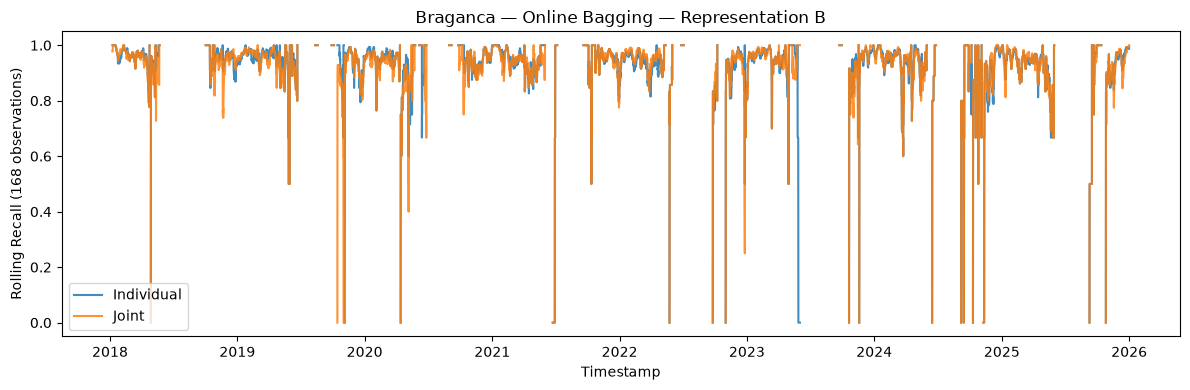

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_b_online_bagging_joint_vs_individual_recall.png


In [41]:

for model_name, rep in selected_configs:
    for city in CITIES:

        filename = (
            f"{city.lower()}_"
            f"{rep.lower()}_"
            f"{model_name}.csv"
        )

        individual = pd.read_csv(
            HISTORY_DIR / filename,
            parse_dates=["timestamp"],
        )

        joint = pd.read_csv(
            JOINT_DIR / "histories" / filename,
            parse_dates=["timestamp"],
        )

        paired = individual[
            ["timestamp", "y_true", "window_recall_positive"]
        ].merge(
            joint[
                ["timestamp", "y_true", "window_recall_positive"]
            ],
            on="timestamp",
            suffixes=("_individual", "_joint"),
            validate="one_to_one",
        )

        assert len(paired) == len(individual) == len(joint)

        assert (
            paired["y_true_individual"]
            == paired["y_true_joint"]
        ).all()

        assert paired["timestamp"].is_monotonic_increasing

        # Exclude incomplete initial 168-event windows.
        recall_cols = [
            "window_recall_positive_individual",
            "window_recall_positive_joint",
        ]

        paired.loc[:166, recall_cols] = np.nan

        fig, ax = plt.subplots(figsize=(12, 4))

        ax.plot(
            paired["timestamp"],
            paired["window_recall_positive_individual"],
            label="Individual",
            alpha=0.85,
        )

        ax.plot(
            paired["timestamp"],
            paired["window_recall_positive_joint"],
            label="Joint",
            alpha=0.85,
        )

        ax.set_title(
            f"{city} — {MODEL_LABELS[model_name]}"
            f" — Representation {rep}"
        )

        ax.set_xlabel("Timestamp")
        ax.set_ylabel("Rolling Recall (168 observations)")
        ax.set_ylim(-0.05, 1.05)
        ax.legend()

        fig.tight_layout()

        output_path = (
            RESULT_FIGURE_DIR
            / f"{city.lower()}_{rep.lower()}_"
              f"{model_name}_joint_vs_individual_recall.png"
        )

        fig.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

        print("Saved:", output_path)
